Clustering Lab


Conor Murray

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
df = pd.read_csv("fb_firm_posts.csv")
mask = (df["post_type"] == "video") | (df["post_type"] == "photo")
df = df[mask].copy()
df["firm_id"] = df["post_id"].str.split("_").str[0]
firm_counts = df["firm_id"].value_counts()
top_firm = firm_counts.index[0]
firm_mask = df["firm_id"] == top_firm
firm_df = df[firm_mask].copy()

print("Firm with the most posts:", top_firm)
print("Number of posts for this firm:", firm_df.shape[0])
print(firm_df["post_type"].value_counts())
print(firm_df[["num_likes", "num_comments", "num_shares"]].describe())

Firm with the most posts: 246675545449582
Number of posts for this firm: 2466
post_type
photo    1869
video     597
Name: count, dtype: int64
         num_likes  num_comments   num_shares
count  2466.000000   2466.000000  2466.000000
mean    317.013382     18.780616     4.637064
std     580.170777     27.141731     6.793033
min       0.000000      0.000000     0.000000
25%      27.000000      3.000000     0.000000
50%     101.000000      6.000000     2.000000
75%     275.750000     24.000000     6.000000
max    4710.000000    154.000000    35.000000


Question 1 - the likes seems to be what I would expect but the shares seem low with the average being just above 4 and even on at the max it is only 35

   num_comments  num_shares
0             0           1
1             1           1
2             8           0
3            23           9
4             7           2
Shape: (2466, 2)


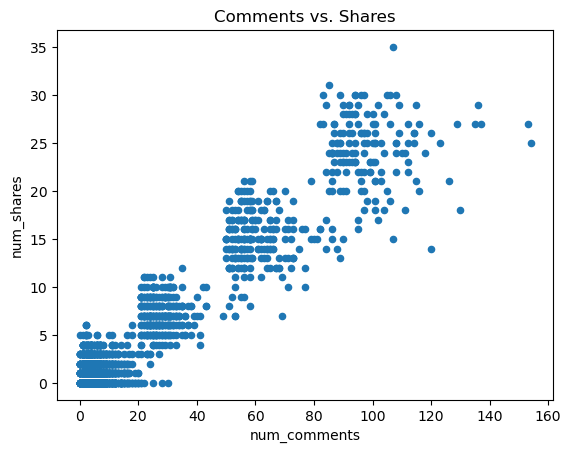

In [6]:
cluster_df = firm_df[["num_comments", "num_shares"]]
print(cluster_df.head())
print("Shape:", cluster_df.shape)
cluster_df.plot.scatter(x="num_comments", y="num_shares",  title="Comments vs. Shares")
plt.show()

Question 2 - there is four obvious groups of clusters, around x = 10, 30, 70, 110

In [8]:
print(cluster_df.describe())

       num_comments   num_shares
count   2466.000000  2466.000000
mean      18.780616     4.637064
std       27.141731     6.793033
min        0.000000     0.000000
25%        3.000000     0.000000
50%        6.000000     2.000000
75%       24.000000     6.000000
max      154.000000    35.000000


In [10]:
scaler = StandardScaler()
scaled_values = scaler.fit_transform(cluster_df)
scaled_df = pd.DataFrame(scaled_values, columns=["num_comments", "num_shares"])
print(scaled_df.describe())
print("Max num_comments after scaling:", scaled_df["num_comments"].max())

       num_comments    num_shares
count  2.466000e+03  2.466000e+03
mean   7.347461e-17 -1.872882e-17
std    1.000203e+00  1.000203e+00
min   -6.920865e-01 -6.827590e-01
25%   -5.815332e-01 -6.827590e-01
50%   -4.709799e-01 -3.882800e-01
75%    1.923401e-01  2.006780e-01
max    4.982984e+00  4.470623e+00
Max num_comments after scaling: 4.9829839261650095


Question 3 -Yes currently the range of comments is 0-154 with the range of shares being 0-35 these are vastly great differences and therefore hard to compare.
If we standardize both variables so that each has a STD of 1 we can equally measure the differnces.

In [11]:
print("Max num_comments after scaling:", scaled_df["num_comments"].max())

Max num_comments after scaling: 4.9829839261650095


Question 4 - The maximum value under the num_comments column is 4.98

[0 0 0 2 0 0 0 1 0 3]


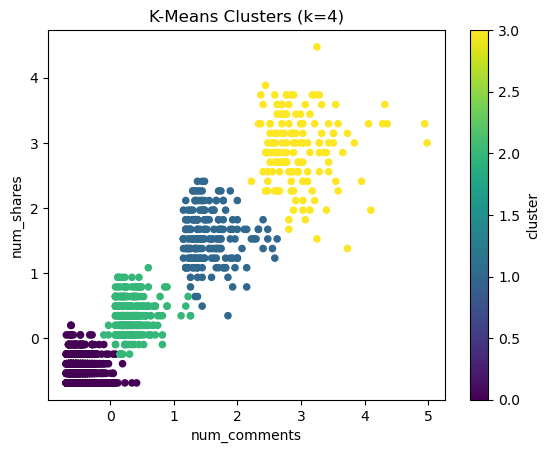

In [16]:
km = KMeans(n_clusters=4)
km.fit(scaled_df)
labels = km.labels_
print(labels[0:10])
plot_df = scaled_df.copy()
plot_df["cluster"] = labels
plot_df.plot.scatter(x="num_comments", y="num_shares", c="cluster", colormap="viridis", title="K-Means Clusters (k=4)")
plt.show()

Question 5 - ^^^

In [18]:
firm_df["cluster"] = labels
print(firm_df["cluster"].value_counts())
print(firm_df.groupby("cluster")[["num_comments", "num_shares", "num_likes"]].mean())
print(pd.crosstab(firm_df["cluster"], firm_df["post_type"]))

cluster
0    1769
2     326
1     219
3     152
Name: count, dtype: int64
         num_comments  num_shares   num_likes
cluster                                      
0            4.994912    1.181458  312.172414
1           60.598174   15.168950  344.296804
2           27.865031    7.095092  352.006135
3           99.486842   24.407895  258.993421
post_type  photo  video
cluster                
0           1343    426
1            166     53
2            240     86
3            120     32


Question 6 - the four clusters show different levels of engagement with a substantial move up the y axis for each cluster. In geneneral shares and comments have a linear 1 to 1 relationship wehre more engagement of one tends to mean more engagement of the other.
My recomendation is to see what types of post and content is getting the high engagement and switch more posts over to that content or style since about 3/4ths of the posts are part of he low engagement group with a small number of high performers, and anything that did very well appears as an outlier. Why these posts did good is important to research.

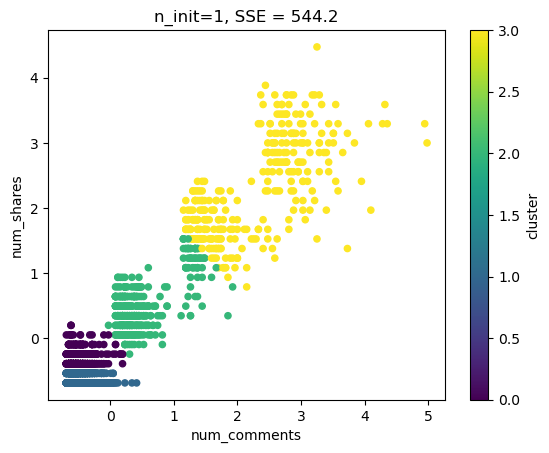

In [19]:
km_one = KMeans(n_clusters=4, n_init=1, init="random")
km_one.fit(scaled_df)
plot_df = scaled_df.copy()
plot_df["cluster"] = km_one.labels_
plot_df.plot.scatter(x="num_comments", y="num_shares", c="cluster", colormap="viridis", title="n_init=1, SSE = " + str(round(km_one.inertia_, 1)))
plt.show()

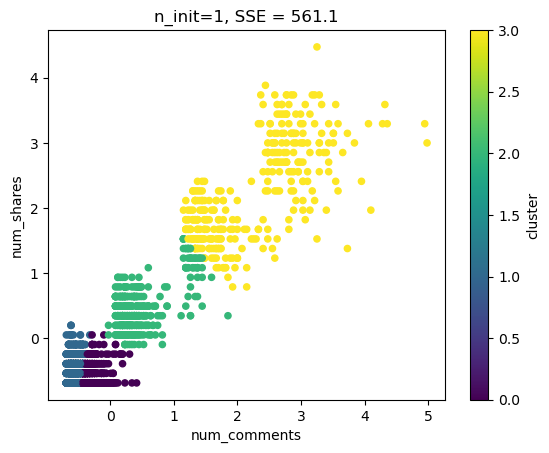

In [23]:
km_one = KMeans(n_clusters=4, n_init=1, init="random")
km_one.fit(scaled_df)
plot_df = scaled_df.copy()
plot_df["cluster"] = km_one.labels_
plot_df.plot.scatter(x="num_comments", y="num_shares", c="cluster", colormap="viridis", title="n_init=1, SSE = " + str(round(km_one.inertia_, 1)))
plt.show()

In [24]:
km = KMeans(n_clusters=4, n_init=10)
km.fit(scaled_df)
print("SSE with n_init=10:", round(km.inertia_, 1))

SSE with n_init=10: 259.0


Question 7 - This is called a local optimum problem, since K means starts at a random point then moves to lower the sum of squared errors with each move its possible that it gets stuck at a locally minumum point that is not the global minimum. The way to fix this issue is to run the K means severl times from several random starting points and then compare to keep the best result. that why we only set N_init it to 1 in our test for 2.5, to intententionly have the model run once so that it could get stuck in a local minimum. versus having it at 10 so that K means can find the best iteration out of 10 runs.

k = 2  SSE = 1012.9
k = 3  SSE = 586.2
k = 4  SSE = 259.0
k = 5  SSE = 218.3
k = 6  SSE = 190.3
k = 7  SSE = 169.6


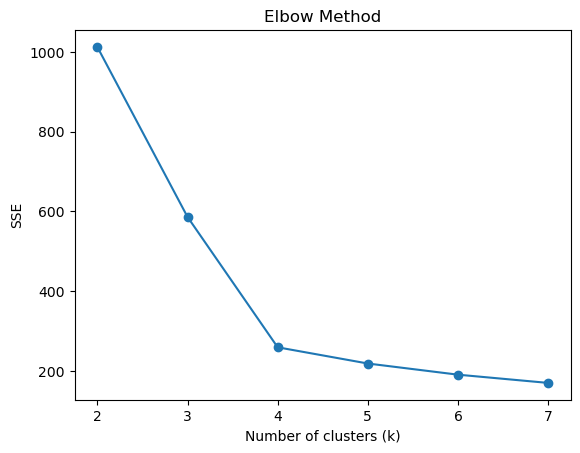

In [26]:
sse_list = []
k_values = []
for k in range(2, 8):
    km_k = KMeans(n_clusters=k, n_init=10)
    km_k.fit(scaled_df)
    sse_list.append(km_k.inertia_)
    k_values.append(k)
    print("k =", k, " SSE =", round(km_k.inertia_, 1))
plt.plot(k_values, sse_list, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("SSE")
plt.title("Elbow Method")
plt.show()

Question 8 - based on this chart the ideal k value is 4 since this is the point with the greatest change in slope.

Question 9 - there are two mistakes in the code, one is that K means is fit on unscaled data which means it wont accurately visualize the comparison.
And secondly the empty list is created inside the loop instead of outside so it is thrown away and gets remade on every pass.

[1012.8797485701808, 587.6448052916301, 258.98658531230444, 238.59951060026944, 203.32937901922773, 198.5582043971342]


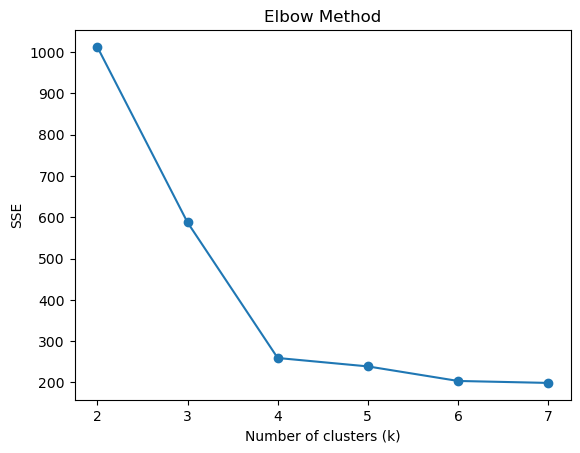

In [27]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

X = firm_df[["num_comments", "num_shares"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

km = KMeans(n_clusters=4)
km.fit(X_scaled)

inertia_values = []
for k in range(2, 8):
    km_k = KMeans(n_clusters=k)
    km_k.fit(X_scaled)
    inertia_values.append(km_k.inertia_)

print(inertia_values)

plt.plot(range(2, 8), inertia_values, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("SSE")
plt.title("Elbow Method")
plt.show()